Successfully saved: rq2.pdf


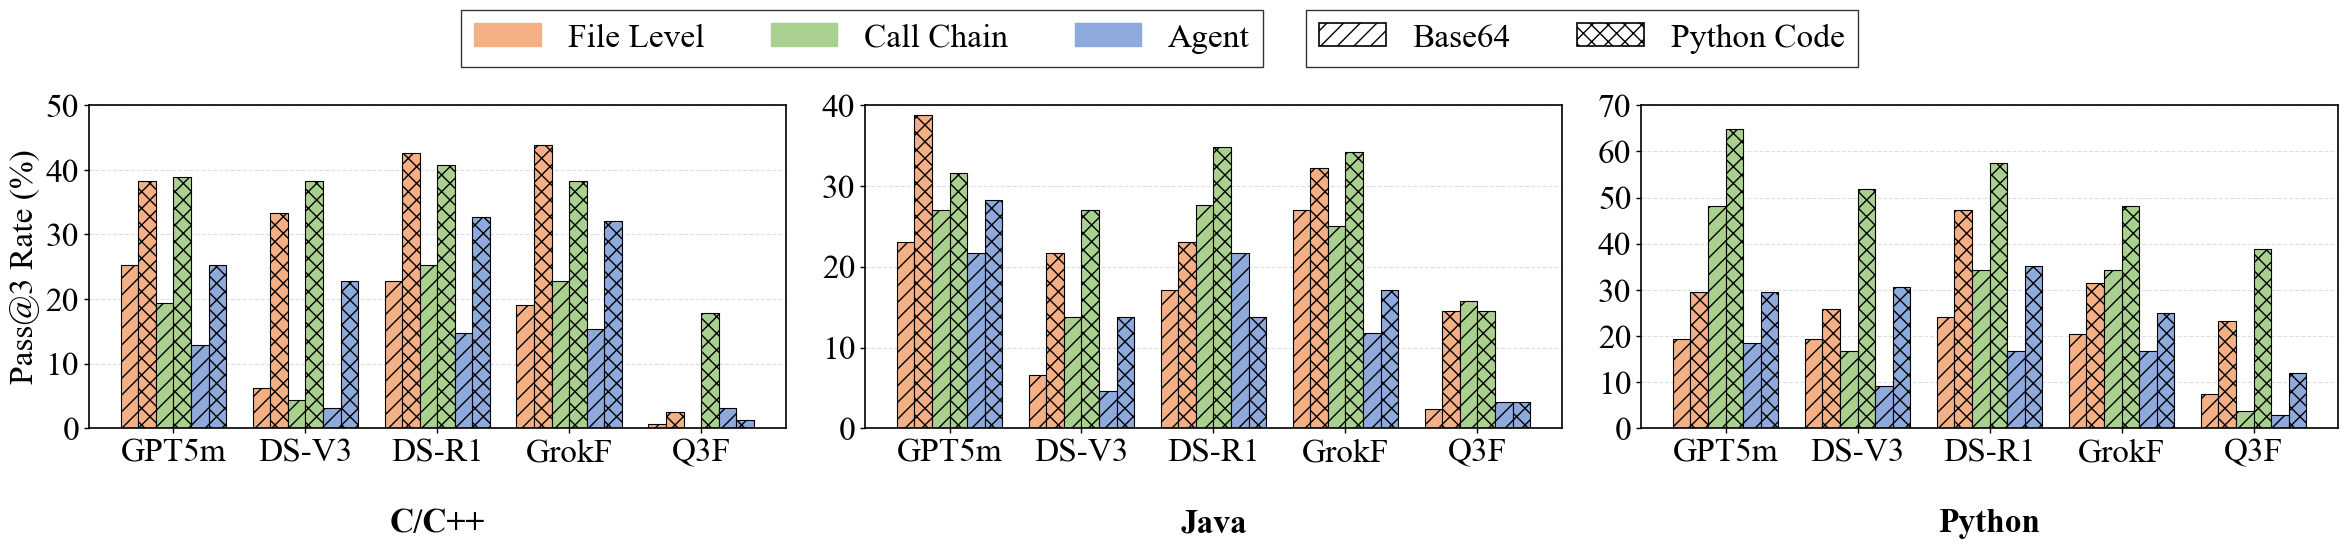

In [ ]:
import matplotlib.pyplot as plt
import numpy as np


FONT_SIZE = 24
plt.rcParams['font.family'] = 'Times New Roman'
plt.rcParams['font.size'] = FONT_SIZE
plt.rcParams['axes.linewidth'] = 1.2
plt.rcParams['xtick.major.width'] = 1.0
plt.rcParams['ytick.major.width'] = 1.0
plt.rcParams['legend.frameon'] = True
plt.rcParams['legend.edgecolor'] = 'black'
plt.rcParams['legend.fancybox'] = False

raw_data = {
    "GPT5m": {
        "base64": {"C/C++": [25.31, 19.41, 12.96], "Java": [23.03, 26.97, 21.71], "Python": [19.44, 48.15, 18.52]},
        "python code": {"C/C++": [38.27, 38.89, 25.31], "Java": [38.82, 31.58, 28.29], "Python": [29.63, 64.81, 29.63]}
    },
    "DS-V3": {
        "base64": {"C/C++": [6.17, 4.32, 3.09], "Java": [6.58, 13.82, 4.61], "Python": [19.44, 16.67, 9.26]},
        "python code": {"C/C++": [33.33, 38.27, 22.84], "Java": [21.71, 26.97, 13.82], "Python": [25.93, 51.85, 30.56]}
    },
    "DS-R1": {
        "base64": {"C/C++": [22.84, 25.31, 14.81], "Java": [17.11, 27.63, 21.71], "Python": [24.07, 34.26, 16.67]},
        "python code": {"C/C++": [42.59, 40.74, 32.72], "Java": [23.03, 34.87, 13.82], "Python": [47.22, 57.41, 35.19]}
    },
    "GrokF": {
        "base64": {"C/C++": [19.14, 22.84, 15.43], "Java": [26.97, 25.00, 11.84], "Python": [20.37, 34.26, 16.67]},
        "python code": {"C/C++": [43.83, 38.27, 32.10], "Java": [32.24, 34.21, 17.11], "Python": [31.48, 48.15, 25.00]}
    },
    "Q3F": {
        "base64": {"C/C++": [0.62, 0.00, 3.09], "Java": [2.39, 15.79, 3.29], "Python": [7.41, 3.70, 2.78]},
        "python code": {"C/C++": [2.47, 17.90, 1.23], "Java": [14.47, 14.47, 3.29], "Python": [23.15, 38.89, 12.04]}
    }
}

context_colors = {"File Level": "#F4B084", "Call Chain": "#A9D08E", "Agent": "#8EA9DB"}
setting_hatches = {"base64": "//", "python code": "xx"}

models = list(raw_data.keys())
contexts = ["File Level", "Call Chain", "Agent"]
settings = ["base64", "python code"]
languages = ["C/C++", "Java", "Python"]


fig, axes = plt.subplots(1, 3, figsize=(24, 6)) 

global_legend_handles_color = []
global_legend_labels_color = []
global_legend_handles_hatch = []
global_legend_labels_hatch = []

added_colors = set()
added_hatches = set()

for idx, target_lang in enumerate(languages):
    ax = axes[idx]  
    
    n_models = len(models)
    n_contexts = len(contexts)
    n_settings = len(settings)
    total_bars_per_model = n_contexts * n_settings
    
    x = np.arange(n_models)
    bar_width = 0.8 / total_bars_per_model

    for i, model in enumerate(models):
        model_base_x = x[i]
        counter = 0
        
        for ctx in contexts:
            ctx_color = context_colors[ctx]
            
            for setting in settings:
                hatch = setting_hatches[setting]
                value = raw_data[model][setting][target_lang][contexts.index(ctx)]
                
                current_offset = counter * bar_width
                center_shift = (total_bars_per_model - 1) * bar_width / 2
                pos = model_base_x - center_shift + current_offset
                
                ax.bar(pos, value, width=bar_width, 
                       color=ctx_color, 
                       hatch=hatch, 
                       edgecolor='black', 
                       linewidth=0.8)
                counter += 1


    ax.set_xticks(x)
    ax.set_xticklabels(models, fontsize=FONT_SIZE, rotation=0, ha='center')
    ax.text(0.5, -0.25, f"{target_lang}", 
        transform=ax.transAxes, 
        fontsize=FONT_SIZE, 
        fontweight='bold', 
        ha='center', 
        va='top')

    if idx == 0:
        ax.set_ylabel("Pass@3 Rate (%)", fontsize=FONT_SIZE)
    
    if target_lang == "Python":
        ax.set_ylim(0, 70)
        ax.set_yticks(np.arange(0, 71, 10))
    elif target_lang == "Java":
        ax.set_ylim(0, 40)
        ax.set_yticks(np.arange(0, 41, 10))
    else:
        ax.set_ylim(0, 50)
        ax.set_yticks(np.arange(0, 51, 10))
        
    ax.grid(axis='y', linestyle='--', alpha=0.4, linewidth=0.8)
    ax.set_axisbelow(True)

    if idx == 0:
        # Color Legend
        for ctx in contexts:
            handle = plt.Rectangle((0,0), 2, 2, color=context_colors[ctx])
            global_legend_handles_color.append(handle)
            global_legend_labels_color.append(ctx)
            added_colors.add(ctx)
        
        # Hatch Legend
        for setting in settings:
            h = setting_hatches[setting]
            handle = plt.Rectangle((0,0), 2, 2, facecolor='white', hatch=h, edgecolor='black', linewidth=1.2)
            global_legend_handles_hatch.append(handle)
            global_legend_labels_hatch.append(setting.replace('_', ' ').title())
            added_hatches.add(setting)

leg1 = fig.legend(global_legend_handles_color, global_legend_labels_color, 
                  loc='upper center', 
                  bbox_to_anchor=(0.37, 1), 
                  borderaxespad=0.,
                  ncol=len(global_legend_labels_color),
                  frameon=True)

leg2 = fig.legend(global_legend_handles_hatch, global_legend_labels_hatch, 
                  loc='upper center', 
                  bbox_to_anchor=(0.67, 1), 
                  borderaxespad=0.,
                  frameon=True,
                  prop={'family': 'Times New Roman', 'size': FONT_SIZE},
                  ncol=len(global_legend_labels_hatch))

plt.tight_layout(rect=[0, 0, 1, 0.92]) 

filename = "rq2.pdf"
plt.savefig(filename, bbox_inches='tight')
print(f"Successfully saved: {filename}")
plt.show()


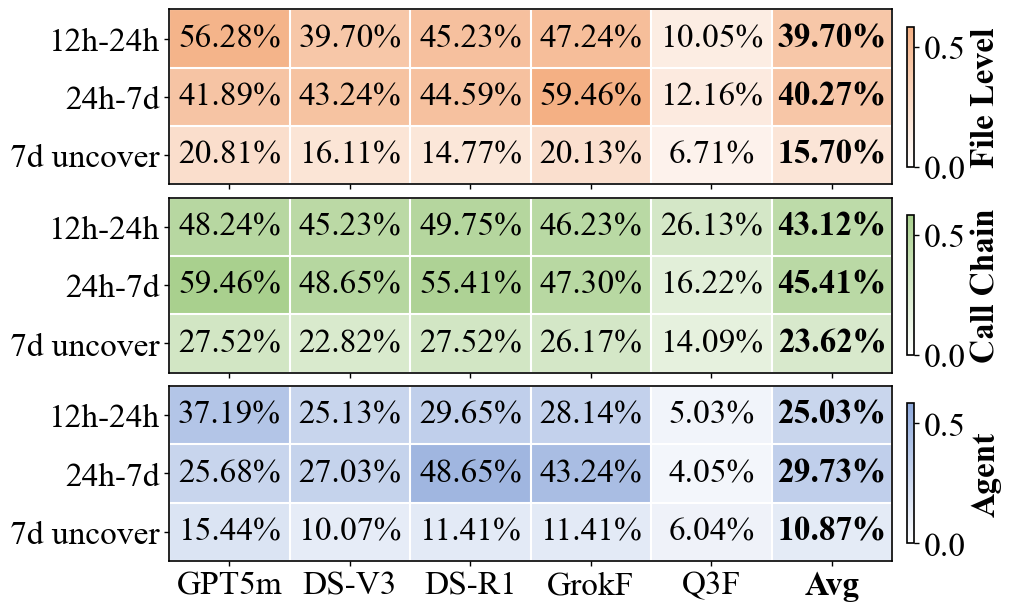

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import colors
from matplotlib.colors import LinearSegmentedColormap, to_rgb

FONT_SIZE = 24

models = [
    "GPT5m",
    "DS-V3",
    "DS-R1",
    "GrokF",
    "Q3F",
    "Avg"
]

difficulty_labels = [
    "12h-24h",
    "24h-7d",
    "7d uncover",
]

totals = {
    "C++":    [102, 45, 15],
    "Java":   [66,  0,  86],
    "Python": [31, 29, 48],
}

call_chain_counts = {
    "C++": {
        "DS-V3": [42, 20,  0], 
        "DS-R1": [42, 24,  0], 
        "Q3F":   [26,  3,  0], 
        "GrokF": [40, 22,  0], 
        "GPT5m": [36, 26,  1],
        "Avg":   [37.2, 19.0, 0.2]
    },
    "Java": {
        "DS-V3": [29,  0, 13], 
        "DS-R1": [37,  0, 15], 
        "Q3F":   [12,  0,  2], 
        "GrokF": [38,  0, 14], 
        "GPT5m": [36,  0, 12],
        "Avg":   [30.4, 0.0, 11.2]
    },
    "Python": {
        "DS-V3": [19, 16, 21], 
        "DS-R1": [20, 17, 26], 
        "Q3F":   [14,  9, 19], 
        "GrokF": [14, 13, 25], 
        "GPT5m": [24, 18, 28],
        "Avg":   [18.2, 14.6, 23.8]
    },
}

single_file_counts = {
    "C++": {
        "DS-V3": [38, 16,  0], 
        "DS-R1": [45, 17,  0], 
        "Q3F":   [4,   0,  0], 
        "GrokF": [41, 29,  1], 
        "GPT5m": [47, 15,  0],
        "Avg":   [35.0, 15.4, 0.2]
    },
    "Java": {
        "DS-V3": [28,  0, 11], 
        "DS-R1": [29,  0,  6], 
        "Q3F":   [5,   0,  1], 
        "GrokF": [37,  0, 12], 
        "GPT5m": [47,  0, 14],
        "Avg":   [29.2, 0.0, 8.8]
    },
    "Python": {
        "DS-V3": [13, 16, 13], 
        "DS-R1": [16, 16, 16], 
        "Q3F":   [11,  9,  9], 
        "GrokF": [16, 15, 17], 
        "GPT5m": [18, 16, 17],
        "Avg":   [14.8, 14.4, 14.4]
    },
}

agent_counts = {
    "C++": {
        "DS-V3": [28,  9,  0], 
        "DS-R1": [30, 23,  0], 
        "Q3F":   [2,   0,  0], 
        "GrokF": [28, 24,  0], 
        "GPT5m": [34,  7,  0],
        "Avg":   [24.4, 12.6, 0.0]
    },
    "Java": {
        "DS-V3": [12,  0,  3], 
        "DS-R1": [17,  0,  4], 
        "Q3F":   [4,   0,  1], 
        "GrokF": [21,  0,  5], 
        "GPT5m": [31,  0, 12],
        "Avg":   [17.0, 0.0, 5.0]
    },
    "Python": {
        "DS-V3": [10, 11, 12], 
        "DS-R1": [12, 13, 13], 
        "Q3F":   [4,   3,  8], 
        "GrokF": [7,   8, 12], 
        "GPT5m": [9,  12, 11],
        "Avg":   [8.4, 9.4, 11.2]
    },
}

context_data = {
    "Single File": single_file_counts,
    "Call Chain Context": call_chain_counts,
    "Agent Context": agent_counts,
}

context_order = ["Single File", "Call Chain Context", "Agent Context"]
user_colors_hex = ["#F4B084", "#A9D08E", "#8EA9DB"]

total_per_bucket = np.sum(np.array(list(totals.values())), axis=0)
total_per_bucket = total_per_bucket.astype(float) 

def compute_pass_rate_matrix(counts_dict):
    matrix = np.zeros((len(models), len(difficulty_labels)), dtype=float)
    for i, model in enumerate(models):
        covered = np.zeros(3, dtype=float) 
        for lang in counts_dict:
            covered += np.array(counts_dict[lang][model])
        matrix[i, :] = covered / total_per_bucket
    return matrix

matrices = {ctx: compute_pass_rate_matrix(data) for ctx, data in context_data.items()}

models_sorted = models 
matrices_sorted = matrices

plt.rcParams.update({
    "font.family": "serif",
    "font.serif": ["Times New Roman"],
    "font.size": FONT_SIZE,
    "axes.titlesize": FONT_SIZE,
    "axes.labelsize": FONT_SIZE,
    "xtick.labelsize": FONT_SIZE,
    "ytick.labelsize": FONT_SIZE,
})

fig, axes = plt.subplots(3, 1, figsize=(10, 6), constrained_layout=True)

vmin, vmax = 0.0, 0.60
norm = colors.PowerNorm(gamma=0.85, vmin=vmin, vmax=vmax)

custom_cmaps = []
for hex_color in user_colors_hex:
    rgb = to_rgb(hex_color)
    cdict = {
        'red':   [(0, 1.0, 1.0), (1, rgb[0], rgb[0])],
        'green': [(0, 1.0, 1.0), (1, rgb[1], rgb[1])],
        'blue':  [(0, 1.0, 1.0), (1, rgb[2], rgb[2])],
    }
    cmap = LinearSegmentedColormap(f'custom_{hex_color}', cdict)
    custom_cmaps.append(cmap)

for idx, ctx_key in enumerate(context_order):
    ax = axes[idx]
    mat = matrices_sorted[ctx_key]
    cmap = custom_cmaps[idx]
    
    mat_transposed = mat.T
    
    im = ax.imshow(mat_transposed, cmap=cmap, norm=norm, aspect="auto")

    ax.set_xticks(np.arange(len(models_sorted)))

    ax.set_xticks(np.arange(len(models_sorted)))

    x_labels = ax.set_xticklabels(models_sorted, rotation=0, ha="center")

    if len(x_labels) > 0:
        x_labels[-1].set_fontweight('bold')

    ax.set_yticks(np.arange(len(difficulty_labels)))
    ax.set_yticklabels(difficulty_labels)

    if idx != len(axes) - 1:
        ax.set_xticklabels([])
        ax.set_xlabel("")
    
    # Grid lines
    ax.set_xticks(np.arange(-0.5, len(models_sorted), 1), minor=True)
    ax.set_yticks(np.arange(-0.5, len(difficulty_labels), 1), minor=True)
    ax.grid(which="minor", color="white", linestyle="-", linewidth=1.5)
    ax.tick_params(which="minor", bottom=False, left=False)

    # Annotate cells
    for i in range(mat_transposed.shape[0]):      
        for j in range(mat_transposed.shape[1]):  
            value = mat_transposed[i, j]
            
            current_model = models_sorted[j]

            if current_model == "Avg":
                ax.text(
                    j, i, f"{value*100:.2f}%", 
                    ha="center", va="center",
                    color="black", fontsize=FONT_SIZE, fontweight="bold"
                )
            else:
                ax.text(
                    j, i, f"{value*100:.2f}%", 
                    ha="center", va="center",
                    color="black", fontsize=FONT_SIZE
                )

    cbar = fig.colorbar(im, ax=ax, shrink=0.8, pad=0.02)
    if ax is axes[0]:
        cbar.set_label("File Level", fontsize=FONT_SIZE, fontweight='bold')
    elif ax is axes[1]:
        cbar.set_label("Call Chain", fontsize=FONT_SIZE, fontweight='bold')
    else:
        cbar.set_label("Agent", fontsize=FONT_SIZE, fontweight='bold')

plt.savefig("rq3_fixed.pdf", bbox_inches='tight', dpi=300)
plt.show()